# 01 — Task 1 data exploration

In [1]:
import json, os, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "task1"
assert DATA.is_dir(), f"No data at {DATA}: put the challenge release in data/"

## 1. Load every case into one table

In [2]:
def load(p):
    return json.load(open(p, encoding="utf8")) if p.exists() else None

raw, rows = {}, []
for c in sorted(os.listdir(DATA)):
    d = DATA / c
    sp  = load(d / "structured-prompt.json")
    cd  = load(d / "prostate-biopsy-decision-clinical-data.json")
    emb = load(d / "prostate-modality-level-neural-representations.json")
    dec = load(d / "prostate-biopsy-decision.json")
    rea = load(d / "prostate-biopsy-decision-reasoning.json")
    raw[c] = {"sp": sp, "cd": cd, "emb": emb, "rea": rea}
    rows.append({
        "case": c, "labeled": dec is not None, "label": dec,
        **{k: sp[k] for k in ["age", "psa", "psad", "psav", "psap", "vol", "cspca", "months",
                              "pirads", "dre", "bx", "medhx", "meds", "enc_type", "mri_hospital"]},
        "fh": cd["family_history"],
        "has_mri_emb": bool(emb and emb.get("MRI image")),
        # text sizes, in characters
        "len_radiology": len(cd["radiology_report"]),
        "n_prev_notes": len(cd["previous_notes"]),
        "len_prev_notes": sum(len(n["text"]) for n in cd["previous_notes"]),
        "n_psa_points": len(cd["psa_trend"]),
        "n_labs": len(cd["laboratory_results"]),
        "len_note_sections": sum(len(s["t"]) for s in sp["note_sections"]),
        "len_structured_prompt": len(json.dumps(sp, ensure_ascii=False)),
        "confidence": rea["confidence"] if rea else None,
        "len_free_text": len(rea["free_text"]) if rea else None,
    })
df = pd.DataFrame(rows).set_index("case")

files = collections.Counter(f for c in df.index for f in os.listdir(DATA / c))
print(f"{len(df)} cases, {df.labeled.sum()} labeled, {(~df.labeled).sum()} unlabeled")
pd.Series(files, name="cases with this file").sort_values(ascending=False).to_frame()

195 cases, 91 labeled, 104 unlabeled


,cases with this file
prostate-biopsy-decision-clinical-data.json,195
structured-prompt.json,195
prostate-modality-level-neural-representations.json,191
prostate-biopsy-decision.json,91
prostate-biopsy-decision-reasoning.json,91


In [25]:
lab = df[df.labeled].copy()   # the 91 cases with a reference decision
lab["y"] = (lab.label == "yes").astype(int)


## 2. Field coverage and missing values

Every field is present in every case, so "missing" shows up as a placeholder value instead. Some placeholders are real answers, though:
- `bx = "None"` means **no prior biopsy**, which is a valid clinical state.
- `meds = "None"` means no medication.
- `pirads = "NA"`, `dre = "Not done"`, `fh = "Unknown"` and `medhx = "Not reported"` are genuinely unknown.

In [4]:
PLACEHOLDERS = {"NA", "Not done", "Unknown", "Not reported", "None", "", "N/A"}

def coverage(source):
    keys = list(raw[df.index[0]][source].keys())
    out = []
    for k in keys:
        vals = [raw[c][source].get(k) for c in df.index]
        out.append({
            "source": source, "field": k,
            "present": sum(k in raw[c][source] for c in df.index),
            "null": sum(v is None for v in vals),
            "placeholder": sum(isinstance(v, str) and v.strip() in PLACEHOLDERS for v in vals),
            "empty list/dict": sum(isinstance(v, (list, dict)) and len(v) == 0 for v in vals),
            "distinct values": len({json.dumps(v, sort_keys=True, ensure_ascii=False) for v in vals}),
        })
    return out

cov = pd.DataFrame(coverage("sp") + coverage("cd")).set_index(["source", "field"])
cov

present  null  placeholder  empty list/dict  \
source field                                                                
sp     case_id                    195     0            0                0   
       pid                        195     0            0                0   
       task                       195     0            0                0   
       psa                        195     0            0                0   
       age                        195     0            0                0   
       months                     195     0            0                0   
       pirads                     195     0            1                0   
       psad                       195     0            0                0   
       psav                       195     0            0                0   
       psap                       195     0            0                0   
       vol                        195     0            0                0   
       dre                        195     0            5                0   
       bx                         195     0           49                0   
       cspca                      195     0            0                0   
       medhx                      195     0           90                0   
       meds                       195     0           98                0   
       notes                      195     0            0                0   
       pmhx                       195     0            0               90   
       allergies                  195     0            0              180   
       vitals                     195     0            0                0   
       enc_dept                   195     0            0                0   
       enc_date                   195     0            0                0   
       enc_ref                    195     0            0                0   
       enc_type                   195     0            0                0   
       note_sections              195     0            0                0   
       occupation                 195     0            0                0   
       marital                    195     0            0                0   
       living                     195     0            0                0   
       next_of_kin                195     0            0                0   
       recent_other               195     0            0               17   
       alcohol                    195     0            0                0   
       exercise                   195     0            0                0   
       ipss                       195     0            0                0   
       admin                      195     0            0                0   
       mri_hospital               195     0            0                0   
       ct                         195   195            0                0   
       active_treatment_flag      195     0            0                0   
cd     radiology_report           195     0            0                0   
       previous_notes             195     0            0                0   
       psa_trend                  195     0            0                0   
       laboratory_results         195     0            0                0   
       family_history             195     0           10                0   

                              distinct values  
source field                                   
sp     case_id                            195  
       pid                                195  
       task                                 1  
       psa                                119  
       age                                 33  
       months                               3  
       pirads                               5  
       psad                               124  
       psav                               151  
       psap                               109  
       vol                                163  
       dre       

In [5]:
print("Constant fields (carry no information):", [f for (_, f), r in cov.iterrows() if r["distinct values"] == 1])
print("\nPlaceholder values per categorical field:")
for k in ["pirads", "dre", "bx", "fh", "medhx", "meds"]:
    vc = df[k].value_counts()
    print(f"  {k:6}", {v: int(n) for v, n in vc.items() if v in PLACEHOLDERS})

Constant fields (carry no information): ['task', 'enc_dept', 'ct', 'active_treatment_flag']

Placeholder values per categorical field:
  pirads {'NA': 1}
  dre    {'Not done': 5}
  bx     {'None': 49}
  fh     {'Unknown': 10}
  medhx  {'Not reported': 90}
  meds   {'None': 98}


## 3. Structured fields: distributions

In [6]:
num = ["age", "psa", "psad", "psav", "psap", "vol", "cspca"]
df[num].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,195.0,65.72,6.84,44.00,61.00,66.00,70.50,82.00
psa,195.0,13.71,24.76,0.20,5.45,7.80,12.00,190.00
psad,195.0,0.29,0.49,0.01,0.11,0.18,0.27,4.10
psav,195.0,2.49,5.16,-0.78,0.77,1.37,2.12,41.57
psap,195.0,11.02,18.91,0.40,4.20,6.20,10.15,153.40
vol,195.0,51.35,25.12,16.40,32.67,46.38,61.00,168.00
cspca,195.0,0.74,0.18,0.00,0.70,0.79,0.85,0.97


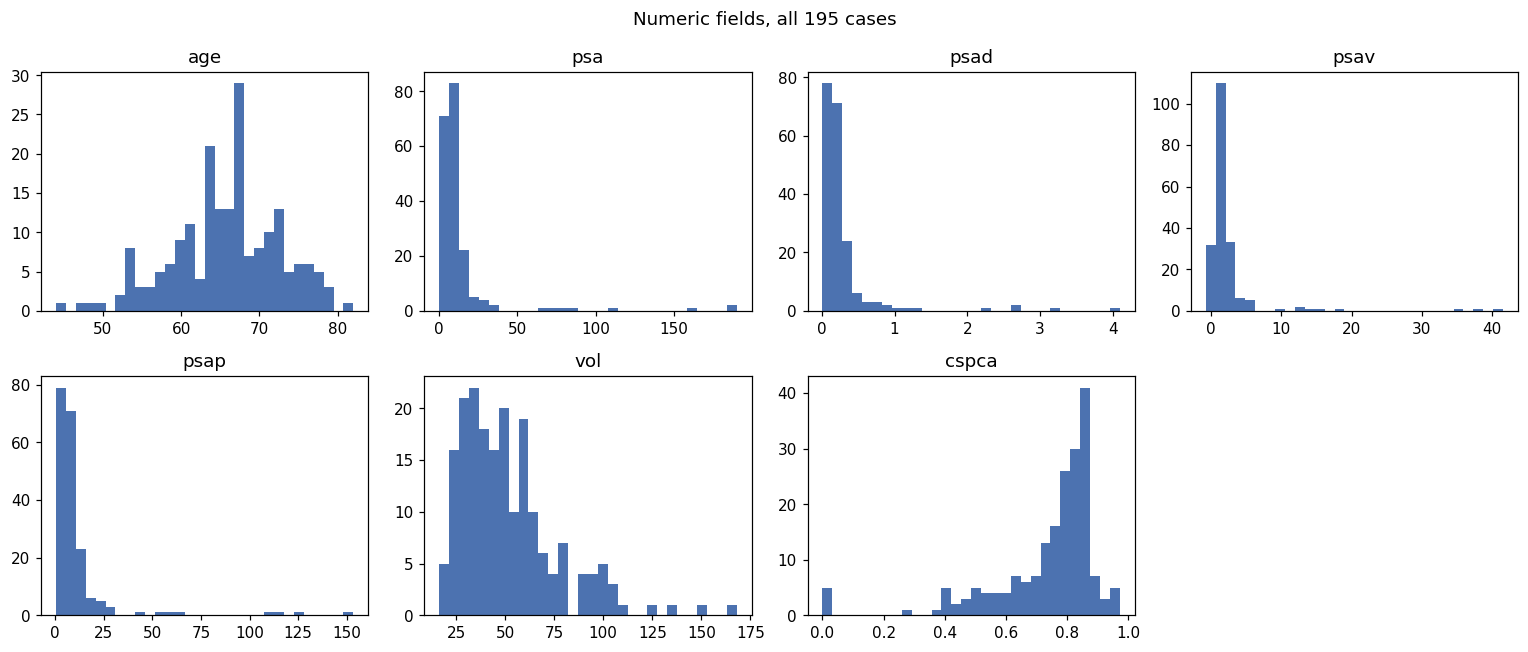

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, k in zip(axes.flat, num):
    ax.hist(df[k], bins=30, color="#4C72B0")
    ax.set_title(k)
axes.flat[-1].axis("off")
fig.suptitle("Numeric fields, all 195 cases")
plt.tight_layout()

In [8]:
# Is psad really psa / vol? Big gaps would mean one of the two values is off.
gap = (df.psa / df.vol - df.psad).abs()
print(f"|psa/vol - psad|: median {gap.median():.3f}, max {gap.max():.3f}, cases > 0.02: {(gap > 0.02).sum()}")

|psa/vol - psad|: median 0.000, max 0.059, cases > 0.02: 5


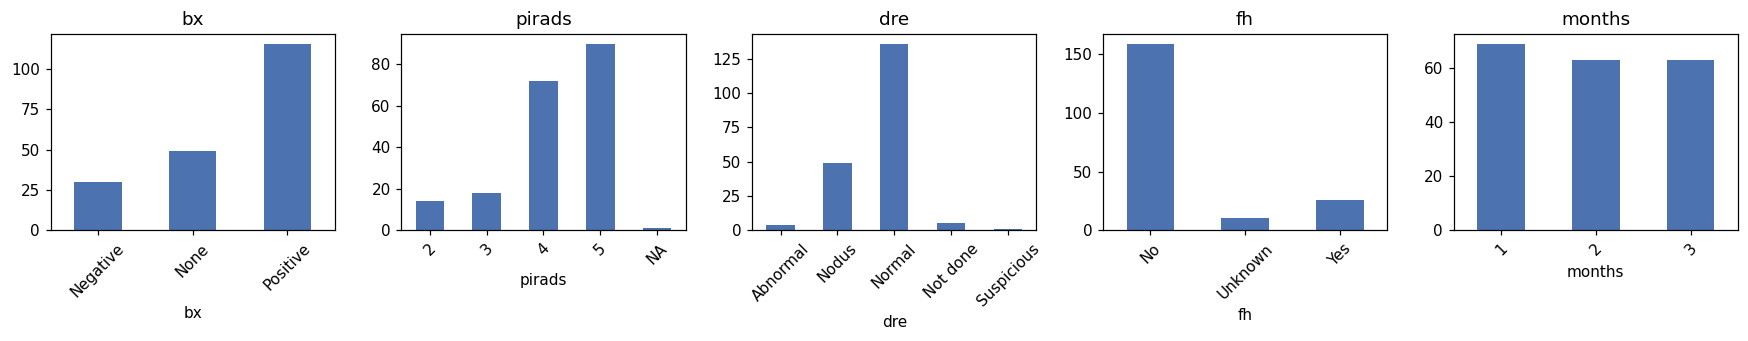

In [9]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, k in zip(axes, ["bx", "pirads", "dre", "fh", "months"]):
    df[k].astype(str).value_counts().sort_index().plot.bar(ax=ax, color="#4C72B0")
    ax.set_title(k); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

In [10]:
print("enc_type vs bx (should match one to one):")
pd.crosstab(df.enc_type, df.bx)

enc_type vs bx (should match one to one):


bx,Negative,None,Positive
enc_type,,,
Follow-up - PSA + MRI,0,49,0
Re-evaluation - prior PCa diagnosis,0,0,116
Re-evaluation - prior negative biopsy,30,0,0


In [11]:
print("Comorbidities (medhx), split on commas:")
pd.Series(collections.Counter(x.strip() for v in df.medhx for x in v.split(","))).sort_values(ascending=False).head(15)

Comorbidities (medhx), split on commas:


Not reported                    90
Hypertension                    44
Hypercholesterolaemia           33
Benign prostatic hyperplasia    29
Osteoarthritis                  27
Chronic kidney disease          26
Type 2 diabetes                 20
Obesity (BMI >30)               15
COPD                            13
Coronary artery disease         12
Atrial fibrillation              7
dtype: int64

## 4. Labeled vs unlabeled cases
Are the 91 labeled cases representative of all 195? If not, numbers measured on them may not carry over.

In [12]:
print("Share of cases per category, labeled vs unlabeled:")
for k in ["bx", "pirads", "dre", "fh"]:
    t = pd.crosstab(df[k], df.labeled, normalize="columns").round(2)
    t.columns = ["unlabeled", "labeled"]
    display(t.T)
df.groupby("labeled")[num].mean().round(2)

Share of cases per category, labeled vs unlabeled:


bx,Negative,None,Positive
unlabeled,0.12,0.24,0.64
labeled,0.20,0.26,0.54


pirads,2,3,4,5,NA
unlabeled,0.09,0.11,0.38,0.43,0.00
labeled,0.05,0.08,0.36,0.49,0.01


dre,Abnormal,Nodus,Normal,Not done,Suspicious
unlabeled,0.03,0.25,0.68,0.04,0.00
labeled,0.01,0.25,0.71,0.01,0.01


fh,No,Unknown,Yes
unlabeled,0.79,0.07,0.14
labeled,0.85,0.03,0.12


,age,psa,psad,psav,psap,vol,cspca
labeled,,,,,,,
False,66.15,11.07,0.24,2.16,8.87,50.97,0.73
True,65.22,16.73,0.36,2.86,13.47,51.79,0.75


## 5. Labels
### 5.1 Decision balance and confidence

In [13]:
print(lab.label.value_counts().to_dict(), f"-> 'yes' rate {lab.y.mean():.3f}")
pd.crosstab(lab.label, lab.confidence, margins=True)

{'yes': 56, 'no': 35} -> 'yes' rate 0.615


confidence,borderline,clear,uncertain,All
label,,,,
no,9,21,5,35
yes,9,37,10,56
All,18,58,15,91


### 5.2 Variable weights given by the reference
For each of the 10 variables, the reference says how much it mattered: not_used / noted / important / decisive.

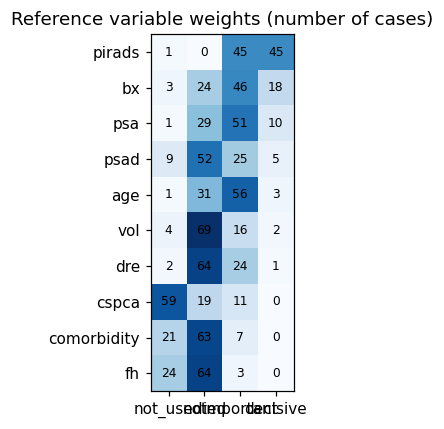

In [14]:
LEVELS = ["not_used", "noted", "important", "decisive"]
w = pd.DataFrame([raw[c]["rea"]["variable_weights"] for c in lab.index], index=lab.index)
wc = w.apply(lambda s: s.value_counts()).reindex(LEVELS).fillna(0).astype(int).T
wc = wc.sort_values(["decisive", "important"], ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(wc.values, cmap="Blues")
ax.set_xticks(range(len(LEVELS)), LEVELS); ax.set_yticks(range(len(wc)), wc.index)
for i in range(wc.shape[0]):
    for j in range(wc.shape[1]):
        ax.text(j, i, wc.values[i, j], ha="center", va="center", fontsize=8)
ax.set_title("Reference variable weights (number of cases)")
plt.tight_layout()

In [15]:
print("Variables marked 'decisive' per case:", w.eq("decisive").sum(axis=1).value_counts().sort_index().to_dict())
print("\nShare of cases where the variable is 'decisive', by decision:")
w.eq("decisive").groupby(lab.label).mean().round(2).T

Variables marked 'decisive' per case: {0: 30, 1: 45, 2: 9, 3: 7}

Share of cases where the variable is 'decisive', by decision:


label,no,yes
psad,0.00,0.09
vol,0.03,0.02
pirads,0.29,0.62
dre,0.00,0.02
fh,0.00,0.00
comorbidity,0.00,0.00
cspca,0.00,0.00
age,0.06,0.02
bx,0.40,0.07
psa,0.14,0.09


### 5.3 Reveal sequence (which tools the reference 'opened') and the explanation

In [16]:
rs = {c: raw[c]["rea"]["reveal_sequence"] for c in lab.index}
print("Tools per case:", collections.Counter(len(v) for v in rs.values()))
print("Tool used at all:", collections.Counter(t for v in rs.values() for t in v).most_common())
print("First tool:", collections.Counter(v[0] for v in rs.values() if v).most_common())
print(f"\nfree_text length (chars): median {lab.len_free_text.median():.0f}, "
      f"min {lab.len_free_text.min():.0f}, max {lab.len_free_text.max():.0f}")

Tools per case: Counter({4: 40, 3: 34, 2: 8, 1: 7, 0: 2})
Tool used at all: [('radiology_report', 88), ('psa_trend', 79), ('previous_notes', 77), ('laboratory_results', 41)]
First tool: [('previous_notes', 68), ('radiology_report', 14), ('psa_trend', 6), ('laboratory_results', 1)]

free_text length (chars): median 73, min 21, max 414


## 6. Which features go with the decision
### 6.1 Categorical: 'yes' rate per value

In [17]:
for k in ["bx", "pirads", "dre", "fh", "months"]:
    t = lab.groupby(lab[k].astype(str)).y.agg(n="size", yes_rate="mean").round(2)
    display(t.T.rename_axis(k, axis=1))

bx,Negative,None,Positive
n,18.00,24.00,49.00
yes_rate,0.72,0.83,0.47


pirads,2,3,4,5,NA
n,5.0,7.00,33.00,45.00,1.0
yes_rate,0.0,0.29,0.73,0.67,0.0


dre,Abnormal,Nodus,Normal,Not done,Suspicious
n,1.0,23.00,65.00,1.0,1.0
yes_rate,0.0,0.57,0.65,1.0,0.0


fh,No,Unknown,Yes
n,77.0,3.00,11.00
yes_rate,0.6,0.67,0.73


months,1,2,3
n,32.00,30.00,29.00
yes_rate,0.69,0.53,0.62


### 6.2 Numeric: distributions by decision, and AUC
AUC of the raw value as a score for 'yes' (0.5 = no signal; below 0.5 = higher values go with 'no').

AUC: {'age': 0.508, 'psa': 0.523, 'psad': 0.556, 'psav': 0.557, 'psap': 0.516, 'vol': 0.364, 'cspca': 0.577}


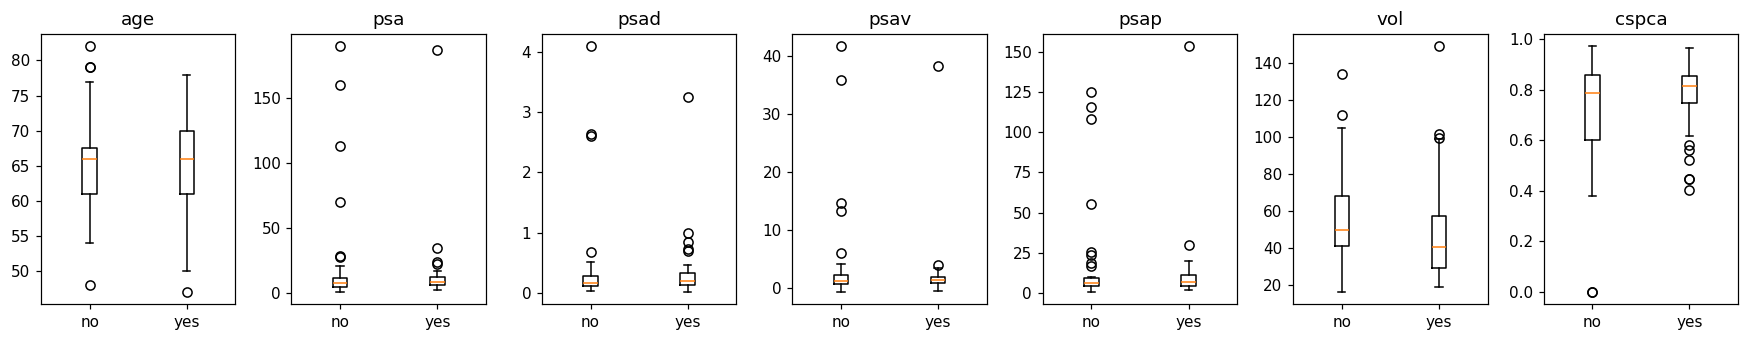

In [18]:
def auc(score, y):
    r = pd.Series(score).rank().values
    n1, n0 = y.sum(), len(y) - y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

print("AUC:", {k: round(float(auc(lab[k].values, lab.y.values)), 3) for k in num})

fig, axes = plt.subplots(1, len(num), figsize=(16, 3.2))
for ax, k in zip(axes, num):
    ax.boxplot([lab.loc[lab.label == v, k] for v in ["no", "yes"]], tick_labels=["no", "yes"])
    ax.set_title(k)
plt.tight_layout()

### 6.3 Simple fixed rules, for reference
No thresholds are tuned here. The cut-offs are the usual clinical ones (PI-RADS ≥ 4, PSAD ≥ 0.15), so this doesn't fit anything to the labels. For comparison, the baseline agent gets accuracy 0.692 and F1(yes) 0.800 on all 91 labeled cases (`results/baseline.md`).

In [19]:
def score(pred, y=lab.y):
    tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum(); fn = ((pred == 0) & (y == 1)).sum()
    return {"accuracy": round((pred == y).mean(), 3), "F1(yes)": round(2 * tp / (2 * tp + fp + fn), 3), "yes_rate": round(pred.mean(), 3)}

pir = pd.to_numeric(lab.pirads, errors="coerce")
rules = {
    "always yes":                  pd.Series(1, index=lab.index),
    "PI-RADS >= 4":                (pir >= 4).astype(int),
    "PSAD >= 0.15":                (lab.psad >= 0.15).astype(int),
    "PI-RADS >= 4 or PSAD >= 0.15": ((pir >= 4) | (lab.psad >= 0.15)).astype(int),
}
pd.DataFrame({k: score(v) for k, v in rules.items()}).T

,accuracy,F1(yes),yes_rate
always yes,0.615,0.762,1.000
PI-RADS >= 4,0.714,0.806,0.857
PSAD >= 0.15,0.571,0.649,0.604
PI-RADS >= 4 or PSAD >= 0.15,0.681,0.791,0.912


In [20]:
print("The same rules by prior biopsy result (accuracy):")
pd.DataFrame({k: {bx: round((v[lab.bx == bx] == lab.y[lab.bx == bx]).mean(), 2) for bx in sorted(lab.bx.unique())}
              for k, v in rules.items()}).T

The same rules by prior biopsy result (accuracy):


,Negative,None,Positive
always yes,0.72,0.83,0.47
PI-RADS >= 4,0.89,1.00,0.51
PSAD >= 0.15,0.50,0.79,0.49
PI-RADS >= 4 or PSAD >= 0.15,0.78,0.96,0.51


## 7. MRI embeddings
The baseline's image predictor is off, but the embeddings could be a feature for us.

In [21]:
shapes = collections.Counter()
for c in df.index:
    e = raw[c]["emb"]
    if e is None:
        shapes["file missing"] += 1
        continue
    for k, v in e.items():
        shapes[(k, f"{len(v)} x {len(v[0]) if v else 0}")] += 1
print(shapes)
print(f"MRI embedding present: {df.has_mri_emb.sum()}/{len(df)} cases, labeled: {lab.has_mri_emb.sum()}/{len(lab)}")

Counter({('MRI image', '1 x 1024'): 191, ('Biopsy slide', '0 x 0'): 191, ('Prostatectomy slide', '0 x 0'): 191, 'file missing': 4})
MRI embedding present: 191/195 cases, labeled: 89/91


In [22]:
# Quick probe: do the 1024-d MRI embeddings predict the decision? 5-fold CV logistic regression on `lab` only.
try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import StratifiedKFold, cross_val_score
    from sklearn.pipeline import make_pipeline
    from sklearn.preprocessing import StandardScaler
    m = lab[lab.has_mri_emb]
    X = np.array([raw[c]["emb"]["MRI image"][0] for c in m.index])
    cv = StratifiedKFold(5, shuffle=True, random_state=0)
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=2000))
    s = cross_val_score(clf, X, m.y, cv=cv, scoring="roc_auc")
    print(f"Embedding -> decision, CV AUC {s.mean():.3f} ± {s.std():.3f} (n={len(m)}; 0.5 = no signal)")
    s2 = cross_val_score(clf, m[["cspca"]].values, m.y, cv=cv, scoring="roc_auc")
    print(f"For comparison, cspca alone: CV AUC {s2.mean():.3f} ± {s2.std():.3f}")
except ImportError:
    print("scikit-learn not installed, skipping the probe")

Embedding -> decision, CV AUC 0.398 ± 0.071 (n=89; 0.5 = no signal)
For comparison, cspca alone: CV AUC 0.562 ± 0.099


## 8. Text lengths and context size
Rough token count = characters / 4 (English text). The run used an Ollama context of 16,384 tokens, and the agent also needs room for the system prompt, guideline chunks and its own reasoning.

In [23]:
lens = df[["len_structured_prompt", "len_radiology", "len_prev_notes", "len_note_sections"]]
display((lens / 4).describe().T[["mean", "50%", "max"]].round(0).rename(columns=lambda c: c + " (tokens)"))
print("Previous notes per case:", df.n_prev_notes.value_counts().sort_index().to_dict())
print("PSA points per case:", df.n_psa_points.value_counts().sort_index().to_dict())
print("Lab results per case:", df.n_labs.value_counts().sort_index().to_dict())

# All tool outputs (clinical-data file) plus the structured prompt
total = np.array([(len(json.dumps(raw[c]["cd"], ensure_ascii=False)) + len(json.dumps(raw[c]["sp"], ensure_ascii=False))) / 4
                  for c in df.index])
print(f"\nStructured prompt + every tool output: median ~{np.median(total):.0f} tokens, max ~{total.max():.0f}")

,mean (tokens),50% (tokens),max (tokens)
len_structured_prompt,693.0,690.0,843.0
len_radiology,229.0,227.0,314.0
len_prev_notes,118.0,109.0,228.0
len_note_sections,337.0,340.0,464.0


Previous notes per case: {1: 101, 2: 94}
PSA points per case: {3: 62, 4: 88, 5: 45}
Lab results per case: {11: 151, 12: 44}

Structured prompt + every tool output: median ~1337 tokens, max ~1599


In [24]:
labs = collections.Counter(i["name"] for c in df.index for i in raw[c]["cd"]["laboratory_results"])
flags = collections.Counter(i["flag"] for c in df.index for i in raw[c]["cd"]["laboratory_results"])
print("Lab tests (cases):", dict(labs.most_common()))
print("Lab flags:", dict(flags))

Lab tests (cases): {'PSA': 195, 'Free PSA': 195, '%Free PSA': 195, 'Haemoglobin': 195, 'WBC': 195, 'Platelets': 195, 'Creatinine': 195, 'eGFR': 195, 'Testosterone': 195, 'Alkaline phosphatase': 195, 'LDH': 195, 'HbA1c': 44}
Lab flags: {'H': 205, '': 1859, 'L': 125}


## 9. Findings

Measured on 12 Oct 2026, on all 195 cases; label findings on the 91 labeled cases.

**Data shape**
- 195 cases, 91 labeled (56 yes / 35 no, so 61.5% "yes"). Every case has every field: missing values show up as placeholders, not nulls.
- Genuinely unknown values are rare: PI-RADS `NA` 1, DRE `Not done` 5, family history `Unknown` 10. `medhx = "Not reported"` (90) and `meds = "None"` (98) are common.
- `bx = "None"` (49) means **no prior biopsy**, not missing. `enc_type` just repeats `bx` (one-to-one).
- Constant fields with no information: `task`, `enc_dept`, `ct` (always null), `active_treatment_flag` (always 0).
- `psad` = `psa / vol` up to rounding (5 cases differ by > 0.02).
- The labeled cases have somewhat more prior-negative biopsies (20% vs 12%) and higher PSA (mean 16.7 vs 11.1) than the unlabeled ones.

**Labels**
- Reference confidence: clear 58, borderline 18, uncertain 15. The baseline answered `clear` on all 91, so confidence is an easy place to gain case score.
- The reference marks 0–3 variables as decisive (30 cases have none). Decisive for "yes": mostly **PI-RADS** (62%). Decisive for "no": mostly the **prior biopsy** (40%) and PI-RADS (29%). `fh`, `comorbidity` and `cspca` are never decisive.
- The reference reveal sequence uses 4 tools (radiology report 88, PSA trend 79, previous notes 77, labs 41), and **never family history**. It usually opens **previous notes first** (68 of 91).
- Reference `free_text` is short: median 73 characters.

**What goes with the decision**
- **Prior biopsy is the key split.** "Yes" rate: no prior biopsy 0.83, prior negative 0.72, prior positive 0.47.
- PI-RADS ≥ 4 alone gets accuracy 0.714 and F1 0.806, slightly better than the baseline agent (0.692 / 0.800). It's near perfect without a positive prior biopsy (1.00 / 0.89) but at chance with one (0.51). That positive-biopsy group (49 of 91 cases) is where the agent's reasoning has to add something.
- Numeric fields alone carry little signal (AUC 0.51–0.58; prostate volume 0.36, i.e. larger glands lean "no").
- MRI embeddings: present for 191/195 cases (1×1024; the biopsy and prostatectomy slide lists are always empty). A logistic regression probe finds **no signal** (CV AUC ~0.40), so they're not worth using as a feature.

**Context size**
- Structured prompt plus all tool outputs is about 1,300–1,600 tokens per case, far below the 16k context. Long contexts aren't the problem; the guideline chunks and the agent's own steps are the bigger share.